# CART Regression — Used-Car Resale Price Prediction

**Name:** Yaswanth kumar reddy  
**Student ID:** 2300031126

**Dataset:** Custom synthetic used-car resale dataset generated inside this notebook using NumPy (1,200 rows). It is not downloaded from Kaggle and is not the Iris or TensorFlow dataset.

**Target:** Predict resale price (₹ lakh) from vehicle attributes.

### Step 1 — Import libraries and configure the experiment

Import the libraries for data handling, visualization, CART regression, model selection, and evaluation. A fixed random seed makes the experiment reproducible.

In [1]:
# 1. Import libraries and configure the experiment
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, KFold, GridSearchCV, cross_validate
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.inspection import permutation_importance
from sklearn.dummy import DummyRegressor

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)
sns.set_theme(style="whitegrid")
print("Libraries imported successfully.")

Libraries imported successfully.


### Step 2 — Generate the dataset

Create a synthetic used-car dataset with 1,200 records. Vehicle age, kilometres driven, engine size, horsepower, mileage, ownership, brand tier, transmission, and fuel type are used to generate resale price. This is a custom-generated dataset, not Iris, Kaggle, or TensorFlow data.

In [2]:
# 2. Create a unique, reproducible used-car dataset
n = 1200
rng = np.random.default_rng(RANDOM_STATE)

age = rng.integers(0, 13, n)
km_driven = np.clip(rng.normal(12500 * (age + 1), 18000, n), 3000, 220000).astype(int)
engine_cc = rng.choice([800, 1000, 1200, 1500, 1800, 2000, 2500], n,
                       p=[.08, .16, .22, .20, .15, .12, .07])
horsepower = np.clip(engine_cc * rng.normal(0.075, 0.012, n), 45, 230)
mileage = np.clip(32 - engine_cc / 115 + rng.normal(0, 2.2, n), 7, 35)
owner_count = rng.choice([1, 2, 3, 4], n, p=[.62, .25, .10, .03])
brand_tier = rng.choice([1, 2, 3], n, p=[.45, .38, .17])  # economy, mid-range, premium
transmission = rng.choice([0, 1], n, p=[.72, .28])        # 0=manual, 1=automatic
fuel_type = rng.choice([0, 1, 2], n, p=[.55, .35, .10])  # petrol, diesel, hybrid

# Nonlinear depreciation, usage penalty, and feature interactions
base_value = 2.2 + 0.0025 * engine_cc + 0.035 * horsepower + 1.35 * brand_tier
age_factor = np.exp(-0.105 * age)
usage_penalty = 0.0000045 * km_driven
owner_penalty = 0.22 * (owner_count - 1)
transmission_bonus = 0.45 * transmission
fuel_bonus = np.select([fuel_type == 1, fuel_type == 2], [0.35, 0.75], default=0)
condition_bonus = 0.45 * np.sin((age + 1) / 2) + 0.25 * (mileage / 30)

noise = rng.normal(0, 0.65, n)
price = (base_value * age_factor - usage_penalty - owner_penalty
         + transmission_bonus + fuel_bonus + condition_bonus + noise)
price = np.clip(price, 0.45, None)

df = pd.DataFrame({
    "age_years": age,
    "km_driven": km_driven,
    "engine_cc": engine_cc,
    "horsepower": horsepower.round(1),
    "mileage_kmpl": mileage.round(1),
    "previous_owners": owner_count,
    "brand_tier": brand_tier,
    "transmission_auto": transmission,
    "fuel_type": fuel_type,
    "resale_price_lakh": price.round(2)
})
df.head()

,age_years,km_driven,engine_cc,horsepower,mileage_kmpl,previous_owners,brand_tier,transmission_auto,fuel_type,resale_price_lakh
0,1,47463,1500,74.2,17.4,1,3,0,0,10.59
1,10,132954,1500,94.2,17.7,1,2,0,0,4.10
2,8,119042,1800,146.5,17.1,1,2,0,0,4.24
3,5,31621,800,61.1,28.0,3,1,0,0,3.77
4,5,54185,1500,115.8,21.3,3,1,0,0,6.61


### Step 3 — Inspect the dataset

Check the dataset dimensions, column data types, descriptive statistics, missing values, and duplicate records before modeling.

In [3]:
# 3. Initial data inspection
print("Shape:", df.shape)
print("\\nData types:")
display(df.dtypes.to_frame("dtype"))
print("\\nSummary statistics:")
display(df.describe().T)
print("\\nMissing values:")
display(df.isna().sum().to_frame("missing_count"))
print("Duplicate rows:", df.duplicated().sum())

Shape: (1200, 10)
\nData types:


,dtype
age_years,int64
km_driven,int64
engine_cc,int64
horsepower,float64
mileage_kmpl,float64
previous_owners,int64
brand_tier,int64
transmission_auto,int64
fuel_type,int64
resale_price_lakh,float64


\nSummary statistics:


,count,mean,std,min,25%,50%,75%,max
age_years,1200.0,6.060833,3.725412,0.0,3.000,6.00,9.0000,12.00
km_driven,1200.0,87743.059167,49607.804822,3000.0,46806.500,87412.00,129558.2500,196791.00
engine_cc,1200.0,1467.500000,464.980920,800.0,1200.000,1500.00,1800.0000,2500.00
horsepower,1200.0,109.985333,38.385705,45.0,80.125,101.70,135.1250,230.00
mileage_kmpl,1200.0,19.211250,4.625279,7.0,16.100,19.60,22.7000,30.50
previous_owners,1200.0,1.520000,0.766000,1.0,1.000,1.00,2.0000,4.00
brand_tier,1200.0,1.720833,0.728016,1.0,1.000,2.00,2.0000,3.00
transmission_auto,1200.0,0.285833,0.451999,0.0,0.000,0.00,1.0000,1.00
fuel_type,1200.0,0.547500,0.666919,0.0,0.000,0.00,1.0000,2.00
resale_price_lakh,1200.0,6.831942,3.543088,0.6,4.035,6.07,9.2825,21.26


\nMissing values:


,missing_count
age_years,0
km_driven,0
engine_cc,0
horsepower,0
mileage_kmpl,0
previous_owners,0
brand_tier,0
transmission_auto,0
fuel_type,0
resale_price_lakh,0


Duplicate rows: 0


### Step 4 — Exploratory data analysis

Visualize the resale-price distribution and its relationships with selected vehicle features. The correlation heatmap helps inspect linear associations between numerical variables.

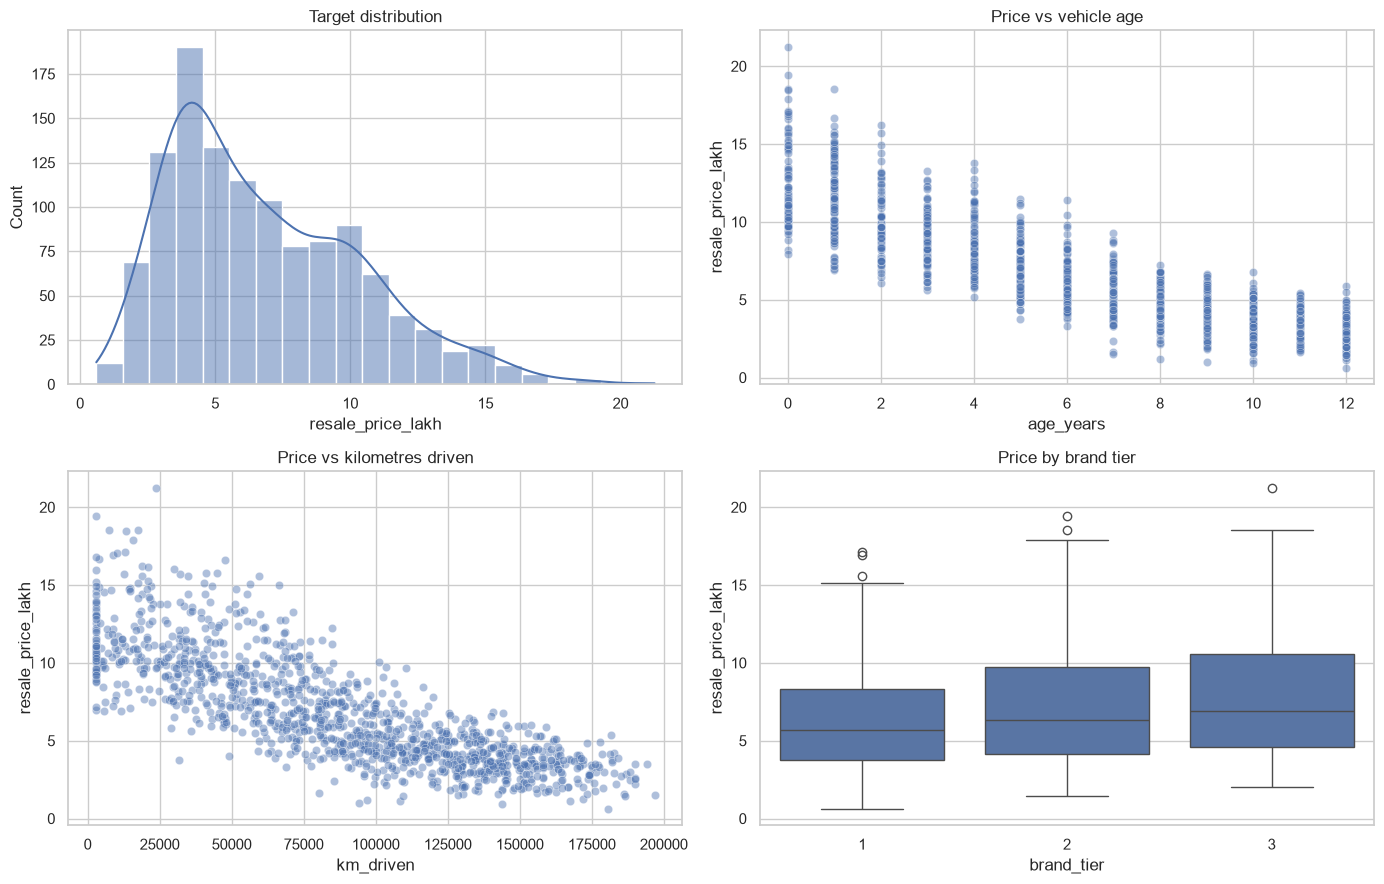

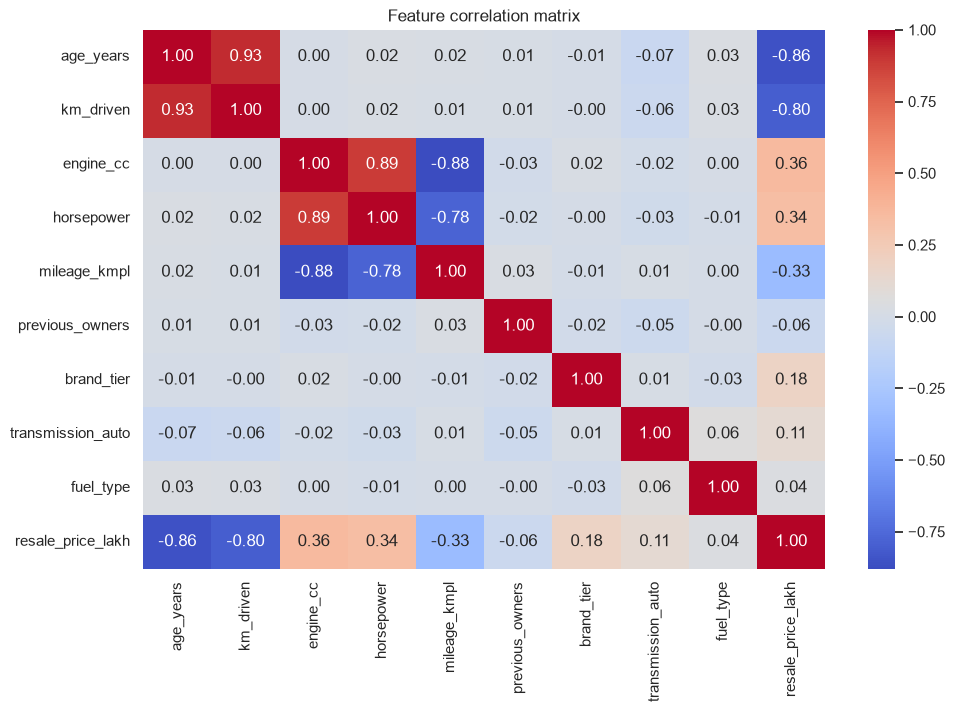

In [4]:
# 4. Exploratory data analysis
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
sns.histplot(df["resale_price_lakh"], kde=True, ax=axes[0, 0])
axes[0, 0].set_title("Target distribution")
sns.scatterplot(data=df, x="age_years", y="resale_price_lakh", alpha=.45, ax=axes[0, 1])
axes[0, 1].set_title("Price vs vehicle age")
sns.scatterplot(data=df, x="km_driven", y="resale_price_lakh", alpha=.45, ax=axes[1, 0])
axes[1, 0].set_title("Price vs kilometres driven")
sns.boxplot(data=df, x="brand_tier", y="resale_price_lakh", ax=axes[1, 1])
axes[1, 1].set_title("Price by brand tier")
plt.tight_layout()
plt.show()

plt.figure(figsize=(11, 7))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Feature correlation matrix")
plt.show()

### Step 5 — Separate features and target

Use all vehicle attributes as input features (X) and resale price as the target (y). Split the data into training and test sets. The test set is held aside for final evaluation.

In [5]:
# 5. Define features and target; create a held-out test set
X = df.drop(columns="resale_price_lakh")
y = df["resale_price_lakh"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE
)
print("Training rows:", len(X_train))
print("Testing rows :", len(X_test))
print("Features     :", list(X.columns))

Training rows: 960
Testing rows : 240
Features     : ['age_years', 'km_driven', 'engine_cc', 'horsepower', 'mileage_kmpl', 'previous_owners', 'brand_tier', 'transmission_auto', 'fuel_type']


### Step 6 — Calculate a CART split manually

For candidate thresholds, calculate parent MSE, each child-node MSE, weighted child MSE, and MSE reduction. The preferred split has the lowest weighted child MSE (equivalently, the largest MSE reduction).

In [6]:
# 6. Manual CART split calculation using parent MSE and weighted child MSE
# Demonstrate every candidate threshold for one feature on a small training sample.
def mse(values):
    values = np.asarray(values)
    return np.mean((values - values.mean()) ** 2)

def evaluate_feature_splits(X_data, y_data, feature, max_candidates=30):
    values = X_data[feature].to_numpy()
    target = y_data.to_numpy()
    thresholds = np.unique(np.quantile(values, np.linspace(0.05, 0.95, max_candidates)))
    parent_mse = mse(target)
    rows = []

    for threshold in thresholds:
        left_mask = values <= threshold
        right_mask = ~left_mask
        if left_mask.sum() == 0 or right_mask.sum() == 0:
            continue

        left_mse = mse(target[left_mask])
        right_mse = mse(target[right_mask])
        weighted_child_mse = (
            left_mask.mean() * left_mse + right_mask.mean() * right_mse
        )
        rows.append({
            "feature": feature,
            "threshold": threshold,
            "left_n": left_mask.sum(),
            "right_n": right_mask.sum(),
            "parent_mse": parent_mse,
            "weighted_child_mse": weighted_child_mse,
            "mse_reduction": parent_mse - weighted_child_mse
        })

    return pd.DataFrame(rows).sort_values("weighted_child_mse")

manual_results = pd.concat([
    evaluate_feature_splits(X_train, y_train, col)
    for col in X_train.columns
], ignore_index=True).sort_values("weighted_child_mse").reset_index(drop=True)

display(manual_results.head(10))
best_manual_split = manual_results.iloc[0]
print("Best manual split:")
print(best_manual_split[["feature", "threshold", "weighted_child_mse", "mse_reduction"]])

,feature,threshold,left_n,right_n,parent_mse,weighted_child_mse,mse_reduction
0,age_years,4.000000,359,601,12.294583,4.960412,7.334170
1,age_years,5.000000,438,522,12.294583,5.152207,7.142376
2,age_years,3.000000,292,668,12.294583,5.659045,6.635538
3,age_years,6.000000,517,443,12.294583,5.735021,6.559562
4,km_driven,79114.139655,435,525,12.294583,5.764516,6.530066
5,km_driven,73554.043103,406,554,12.294583,5.835390,6.459192
6,km_driven,83549.353448,465,495,12.294583,5.898818,6.395764
7,km_driven,70301.172414,376,584,12.294583,5.976345,6.318237
8,km_driven,88281.005172,495,465,12.294583,6.000251,6.294332
9,km_driven,61025.641379,316,644,12.294583,6.246024,6.048558


Best manual split:
feature               age_years
threshold                   4.0
weighted_child_mse     4.960412
mse_reduction           7.33417
Name: 0, dtype: object


### Step 7 — Train the full CART regression tree

Fit a decision tree without depth or leaf-size restrictions. Compare training and test RMSE, MAE, and R², and inspect tree depth and leaf count to assess complexity.

In [7]:
# 7. Fit an unrestricted CART regression tree
full_tree = DecisionTreeRegressor(random_state=RANDOM_STATE)
full_tree.fit(X_train, y_train)

def regression_metrics(model, X_part, y_part, label):
    predictions = model.predict(X_part)
    return {
        "Model": label,
        "RMSE": np.sqrt(mean_squared_error(y_part, predictions)),
        "MAE": mean_absolute_error(y_part, predictions),
        "R2": r2_score(y_part, predictions)
    }

full_results = pd.DataFrame([
    regression_metrics(full_tree, X_train, y_train, "Full tree - train"),
    regression_metrics(full_tree, X_test, y_test, "Full tree - test")
])
display(full_results)
print("Tree depth:", full_tree.get_depth())
print("Number of leaves:", full_tree.get_n_leaves())

,Model,RMSE,MAE,R2
0,Full tree - train,0.000000,0.000000,1.000000
1,Full tree - test,1.300277,0.990333,0.875063


Tree depth: 20
Number of leaves: 953


### Step 8 — Visualize the full tree

Display the upper levels of the fitted tree. Each node shows its split rule, sample count, predicted value, and impurity. The plot is limited to three levels for readability.

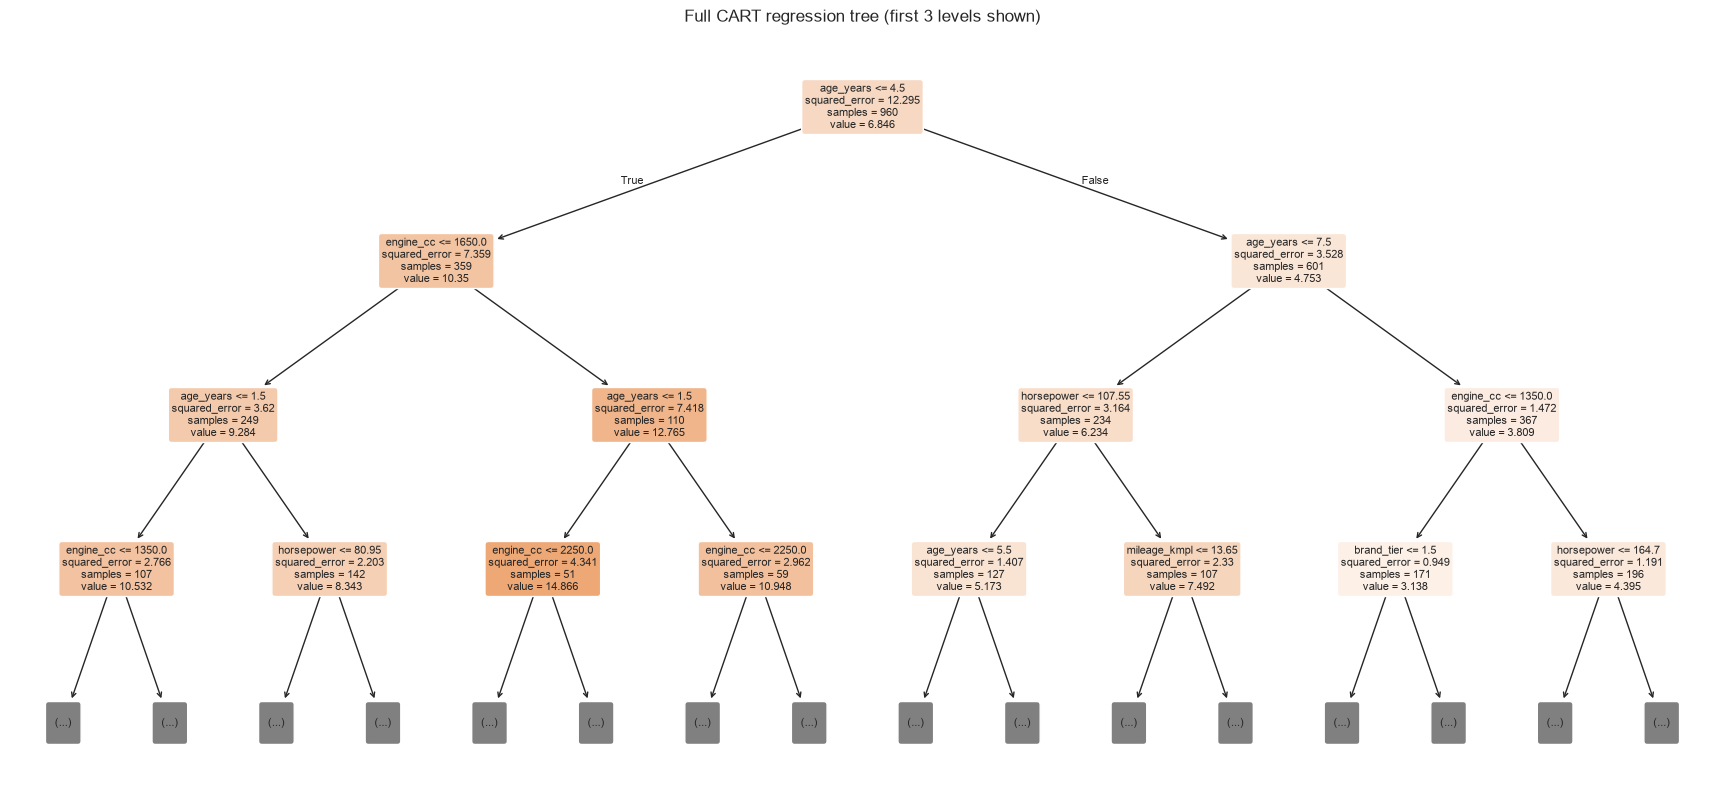

In [8]:
# 8. Visualize the first levels of the full tree
plt.figure(figsize=(22, 10))
plot_tree(full_tree, feature_names=X.columns, filled=True, rounded=True,
          max_depth=3, fontsize=8, impurity=True)
plt.title("Full CART regression tree (first 3 levels shown)")
plt.show()

### Step 9 — Establish a baseline

Train a mean-prediction baseline. A CART model should outperform this simple reference on held-out data to demonstrate useful predictive learning.

In [9]:
# 9. Baseline: predict the training-set mean for every observation
baseline = DummyRegressor(strategy="mean")
baseline.fit(X_train, y_train)

baseline_results = pd.DataFrame([
    regression_metrics(baseline, X_train, y_train, "Mean baseline - train"),
    regression_metrics(baseline, X_test, y_test, "Mean baseline - test")
])
display(baseline_results)

,Model,RMSE,MAE,R2
0,Mean baseline - train,3.506363,2.879064,0.000000
1,Mean baseline - test,3.679367,3.085348,-0.000382


### Step 10 — Apply pre-pruning

Use GridSearchCV with five-fold cross-validation on the training set to select max_depth, min_samples_leaf, and min_samples_split. These constraints stop the tree from growing too complex.

In [10]:
# 10. Pre-pruning: tune maximum depth and minimum leaf size with training-only CV
preprune_grid = {
    "max_depth": [2, 3, 4, 5, 6, 8, 10, None],
    "min_samples_leaf": [1, 2, 5, 10, 15, 20],
    "min_samples_split": [2, 5, 10, 20]
}
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

preprune_search = GridSearchCV(
    DecisionTreeRegressor(random_state=RANDOM_STATE),
    param_grid=preprune_grid,
    scoring="neg_root_mean_squared_error",
    cv=cv,
    n_jobs=-1,
    return_train_score=True
)
preprune_search.fit(X_train, y_train)

print("Best pre-pruning parameters:", preprune_search.best_params_)
print("Best CV RMSE:", -preprune_search.best_score_)
prepruned_tree = preprune_search.best_estimator_

display(pd.DataFrame([
    regression_metrics(prepruned_tree, X_train, y_train, "Pre-pruned - train"),
    regression_metrics(prepruned_tree, X_test, y_test, "Pre-pruned - test")
]))

Best pre-pruning parameters: {'max_depth': 10, 'min_samples_leaf': 10, 'min_samples_split': 2}
Best CV RMSE: 1.1366133693383877


,Model,RMSE,MAE,R2
0,Pre-pruned - train,0.855503,0.667994,0.940471
1,Pre-pruned - test,1.021532,0.783106,0.922888


### Step 11 — Generate the cost-complexity pruning path

Fit a tree on the training data and obtain candidate ccp_alpha values. Increasing ccp_alpha applies a stronger penalty to additional leaves, producing simpler trees. The plot uses matching alpha and impurity arrays.

Number of candidate alpha values: 835


ValueError: x and y must have same first dimension, but have shapes (835,) and (888,)

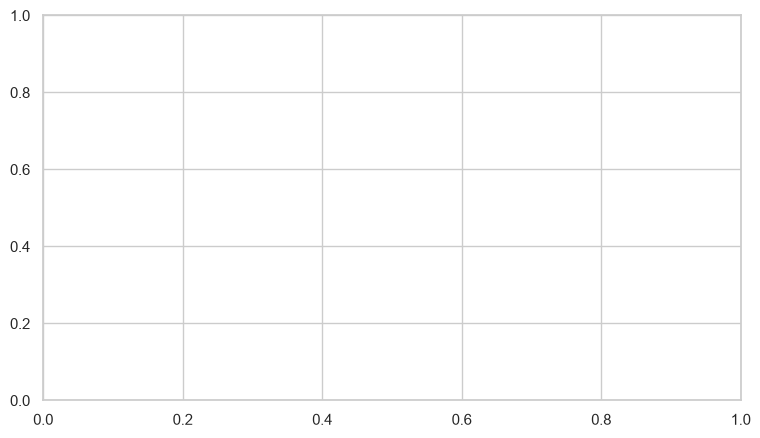

In [11]:
# 11. Post-pruning: obtain the cost-complexity pruning path
path_tree = DecisionTreeRegressor(random_state=RANDOM_STATE)
path_tree.fit(X_train, y_train)
path = path_tree.cost_complexity_pruning_path(X_train, y_train)
ccp_alphas = np.unique(path.ccp_alphas)
ccp_alphas = ccp_alphas[ccp_alphas >= 0]

print("Number of candidate alpha values:", len(ccp_alphas))
plt.figure(figsize=(9, 5))
plt.plot(ccp_alphas, path.impurities,
         marker="o", drawstyle="steps-post")
plt.xlabel("ccp_alpha")
plt.ylabel("Total leaf impurity")
plt.title("Cost-complexity pruning path")
plt.show()

### Step 12 — Select post-pruning strength with cross-validation

Evaluate candidate ccp_alpha values using five-fold cross-validation on training data only. Select the alpha with the lowest validation RMSE; the test set is not used for this selection.

In [ ]:
# 12. Evaluate pruning candidates using cross-validation on training data only
# Limit to a representative set of alpha values if the path is very long.
alpha_candidates = np.unique(np.quantile(ccp_alphas, np.linspace(0, 1, min(35, len(ccp_alphas)))))
postprune_search = GridSearchCV(
    DecisionTreeRegressor(random_state=RANDOM_STATE),
    param_grid={"ccp_alpha": alpha_candidates},
    scoring="neg_root_mean_squared_error",
    cv=cv,
    n_jobs=-1,
    return_train_score=True
)
postprune_search.fit(X_train, y_train)

print("Best post-pruning alpha:", postprune_search.best_params_["ccp_alpha"])
print("Best CV RMSE:", -postprune_search.best_score_)
postpruned_tree = postprune_search.best_estimator_

post_cv_results = pd.DataFrame(postprune_search.cv_results_)
plt.figure(figsize=(9, 5))
plt.plot(post_cv_results["param_ccp_alpha"].astype(float),
         -post_cv_results["mean_test_score"], marker="o", label="CV RMSE")
plt.xlabel("ccp_alpha")
plt.ylabel("Cross-validation RMSE")
plt.title("Selecting ccp_alpha using training CV")
plt.legend()
plt.show()

### Step 13 — Compare all models

Compare the baseline, full tree, pre-pruned tree, and post-pruned tree on both training and test data using RMSE, MAE, and R².

In [ ]:
# 13. Compare full, pre-pruned, post-pruned trees and the baseline
models = {
    "Mean baseline": baseline,
    "Full tree": full_tree,
    "Pre-pruned tree": prepruned_tree,
    "Post-pruned tree": postpruned_tree
}

comparison_rows = []
for model_name, model in models.items():
    comparison_rows.append(regression_metrics(model, X_train, y_train, model_name + " - train"))
    comparison_rows.append(regression_metrics(model, X_test, y_test, model_name + " - test"))

comparison = pd.DataFrame(comparison_rows)
display(comparison.round(4))

test_comparison = comparison[comparison["Model"].str.endswith("- test")].copy()
test_comparison["Model"] = test_comparison["Model"].str.replace(" - test", "", regex=False)
test_comparison = test_comparison.sort_values("RMSE")
display(test_comparison)

### Step 14 — Examine overfitting

Plot training and test RMSE side by side. A large gap, especially when training RMSE is much lower, is a warning sign that the model may be overfitting.

In [ ]:
# 14. Visualize train vs test RMSE to inspect overfitting
plot_data = comparison.copy()
plot_data["Dataset"] = np.where(plot_data["Model"].str.endswith("- train"), "Train", "Test")
plot_data["Model"] = plot_data["Model"].str.replace(" - train", "", regex=False).str.replace(" - test", "", regex=False)

plt.figure(figsize=(11, 5))
sns.barplot(data=plot_data, x="Model", y="RMSE", hue="Dataset")
plt.xticks(rotation=15)
plt.title("Training and test RMSE comparison")
plt.tight_layout()
plt.show()

### Step 15 — Choose the final tree

Compare the best pre-pruning and post-pruning cross-validation scores. Select the model with the better training-only CV score, without using test-set performance for model selection.

In [ ]:
# 15. Select the final model using training CV performance; test set remains untouched
# Compare the best pre-pruned and post-pruned CV scores.
candidate_cv = pd.DataFrame({
    "candidate": ["Pre-pruned", "Post-pruned"],
    "cv_rmse": [-preprune_search.best_score_, -postprune_search.best_score_]
})
display(candidate_cv)

if preprune_search.best_score_ >= postprune_search.best_score_:
    selected_model = prepruned_tree
    selected_name = "Pre-pruned CART"
else:
    selected_model = postpruned_tree
    selected_name = "Post-pruned CART"

print("Selected model:", selected_name)
print("Selected tree depth:", selected_model.get_depth())
print("Selected tree leaves:", selected_model.get_n_leaves())

### Step 16 — Evaluate on the held-out test set

Calculate final test RMSE, MAE, and R² for the selected model and compare its RMSE with the mean baseline. These test metrics estimate generalization to unseen records.

In [ ]:
# 16. Final held-out test evaluation
final_predictions = selected_model.predict(X_test)
final_metrics = {
    "Selected model": selected_name,
    "Test RMSE": np.sqrt(mean_squared_error(y_test, final_predictions)),
    "Test MAE": mean_absolute_error(y_test, final_predictions),
    "Test R2": r2_score(y_test, final_predictions),
    "Baseline test RMSE": np.sqrt(mean_squared_error(y_test, baseline.predict(X_test)))
}
display(pd.DataFrame([final_metrics]).round(4))

### Step 17 — Analyze prediction errors

Compare actual and predicted prices and inspect residuals (actual minus predicted). The residual plots can reveal systematic errors, unusual observations, or changing error spread.

In [ ]:
# 17. Actual vs predicted values and residual diagnostics
residuals = y_test.to_numpy() - final_predictions

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].scatter(y_test, final_predictions, alpha=.6)
low = min(y_test.min(), final_predictions.min())
high = max(y_test.max(), final_predictions.max())
axes[0].plot([low, high], [low, high], "r--")
axes[0].set_xlabel("Actual price (₹ lakh)")
axes[0].set_ylabel("Predicted price (₹ lakh)")
axes[0].set_title("Actual vs predicted")

axes[1].scatter(final_predictions, residuals, alpha=.6)
axes[1].axhline(0, color="red", linestyle="--")
axes[1].set_xlabel("Predicted price (₹ lakh)")
axes[1].set_ylabel("Residual (actual - predicted)")
axes[1].set_title("Residuals vs predicted")
plt.tight_layout()
plt.show()

sns.histplot(residuals, kde=True)
plt.title("Residual distribution")
plt.xlabel("Residual (₹ lakh)")
plt.show()

### Step 18 — Inspect tree feature importance

Rank features using the selected tree's impurity-based importance. These scores show how much features contributed to reducing node impurity in this fitted tree; they do not prove causation.

In [ ]:
# 18. Feature importance from the selected CART model
importance = pd.Series(selected_model.feature_importances_, index=X.columns)
importance = importance.sort_values(ascending=False)
display(importance.to_frame("impurity_importance"))

plt.figure(figsize=(9, 5))
sns.barplot(x=importance.values, y=importance.index)
plt.title("Selected tree: feature importance")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.show()

### Step 19 — Validate importance with permutation

Shuffle one feature at a time in the test set and measure the resulting score decrease. Larger decreases indicate greater reliance by the fitted model. Correlated features can share or mask importance.

In [ ]:
# 19. Permutation importance on the held-out test set
# This measures the drop in model score when a feature is shuffled.
perm = permutation_importance(
    selected_model, X_test, y_test,
    n_repeats=20, random_state=RANDOM_STATE,
    scoring="neg_root_mean_squared_error", n_jobs=-1
)
permutation_scores = pd.DataFrame({
    "feature": X.columns,
    "importance_mean": perm.importances_mean,
    "importance_std": perm.importances_std
}).sort_values("importance_mean", ascending=False)

display(permutation_scores)
plt.figure(figsize=(9, 5))
sns.barplot(data=permutation_scores, x="importance_mean", y="feature")
plt.title("Permutation importance on test data")
plt.xlabel("Decrease in score when shuffled (higher = more useful)")
plt.ylabel("Feature")
plt.show()

### Step 20 — Inspect individual predictions

Display selected test records with actual price, predicted price, and absolute error. This helps identify examples where the model performs poorly.

In [ ]:
# 20. Inspect a few individual predictions
prediction_check = X_test.copy()
prediction_check["actual_price_lakh"] = y_test
prediction_check["predicted_price_lakh"] = final_predictions
prediction_check["absolute_error"] = np.abs(
    prediction_check["actual_price_lakh"] - prediction_check["predicted_price_lakh"]
)
display(prediction_check.sort_values("absolute_error", ascending=False).head(10))

### Step 21 — Predict for a new vehicle

Create one example vehicle using the same feature names and order as the training data, then use the selected model to estimate its resale price.

In [ ]:
# 21. Predict resale price for a new example
new_car = pd.DataFrame([{
    "age_years": 4,
    "km_driven": 52000,
    "engine_cc": 1500,
    "horsepower": 112.5,
    "mileage_kmpl": 20.0,
    "previous_owners": 1,
    "brand_tier": 2,
    "transmission_auto": 1,
    "fuel_type": 0
}])

predicted_price = selected_model.predict(new_car)[0]
print(f"Estimated resale price: ₹{predicted_price:.2f} lakh")

### Step 22 — Export results

Save the generated dataset and model-comparison table as CSV files so they can be reused or submitted alongside the notebook.

In [ ]:
# 22. Export the generated dataset and model comparison tables
df.to_csv("used_car_cart_dataset.csv", index=False)
comparison.to_csv("cart_model_comparison.csv", index=False)
print("Saved: used_car_cart_dataset.csv")
print("Saved: cart_model_comparison.csv")

## Conclusion

- Regression CART chooses splits that reduce squared error (MSE).
- Compare train and test RMSE to identify overfitting.
- Pre-pruning limits tree growth; cost-complexity post-pruning penalizes extra leaves.
- Cross-validation selects settings using training data; the test set is reserved for final evaluation.
- Compare against the mean baseline before claiming useful predictive performance.
- Feature importance describes predictive contribution, not causation.